# Exame B - Previsão da Demanda de Bicicletas Compartilhadas
**Alunos:**  
Claudio Henrique Lopes Mendes (202506840010)  
Theo Machado Silveira Mello (202506840004)  

---

## Resumo

Este trabalho apresenta uma análise exploratória dos dados de demanda de bicicletas compartilhadas, utilizando o conjunto de dados Seoul Bike Sharing Demand. Nesta primeira etapa, são investigadas as características das variáveis, a qualidade dos dados, a distribuição da demanda e as possíveis relações entre a quantidade de bicicletas alugadas e as variáveis meteorológicas, temporais e categóricas.

O objetivo da análise exploratória é identificar padrões, comportamentos relevantes e possíveis variáveis explicativas para a demanda de bicicletas, fornecendo uma base para as etapas posteriores de testes de hipóteses e construção do modelo de regressão.

## Seção 1: Exploração dos Dados

Nesta seção, será realizada uma análise exploratória do conjunto de dados de bicicletas compartilhadas. Inicialmente, serão verificadas as dimensões, os tipos das variáveis e algumas informações gerais sobre os dados.

In [ ]:
# Objetivo: Importar as bibliotecas utilizadas no trabalho.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1


In [ ]:
# Objetivo: Carregar o dataset de bicicletas compartilhadas.
df = pd.read_csv("bike_sharing.csv")

print("Dimensões:", df.shape)
display(df.head())

Dimensões: (7008, 14)


,Date,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,Dew_Point_Temperature,Solar_Radiation,Rainfall,Snowfall,Seasons,Holiday,Functioning_Day
0,18/10/2018,165,4,8.1,78,0.6,2000,4.4,0.00,0.0,0.0,Autumn,No Holiday,Yes
1,30/03/2018,115,4,9.9,67,1.1,820,4.0,0.00,0.0,0.0,Spring,No Holiday,Yes
2,19/12/2017,55,5,-3.9,66,0.7,1209,-9.3,0.00,0.0,2.6,Winter,No Holiday,Yes
3,05/05/2018,1024,11,20.2,41,3.1,1789,6.5,2.56,0.0,0.0,Spring,No Holiday,Yes
4,24/04/2018,157,1,10.1,83,1.6,2000,7.3,0.00,0.0,0.0,Spring,No Holiday,Yes


### 1.2 Conhecendo o conjunto de dados

O conjunto de dados utilizado contém registros horários da utilização de bicicletas compartilhadas durante o período de dezembro de 2017 a novembro de 2018.

A variável de interesse é `Rented_Bike_Count`, que representa a quantidade de bicicletas alugadas em determinado horário. As demais variáveis descrevem características temporais, condições meteorológicas e informações sobre o funcionamento do serviço.

In [ ]:
# Objetivo: Inspecionar tipos, valores ausentes e estatísticas básicas.
display(df.info())
display(df.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7008 entries, 0 to 7007
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   7008 non-null   object 
 1   Rented_Bike_Count      7008 non-null   int64  
 2   Hour                   7008 non-null   int64  
 3   Temperature            7008 non-null   float64
 4   Humidity               7008 non-null   int64  
 5   Wind_Speed             7008 non-null   float64
 6   Visibility             7008 non-null   int64  
 7   Dew_Point_Temperature  7008 non-null   float64
 8   Solar_Radiation        7008 non-null   float64
 9   Rainfall               7008 non-null   float64
 10  Snowfall               7008 non-null   float64
 11  Seasons                7008 non-null   object 
 12  Holiday                7008 non-null   object 
 13  Functioning_Day        7008 non-null   object 
dtypes: float64(6), int64(4), object(4)
memory usage: 766.6+ 

None

,count,mean,std,min,25%,50%,75%,max
Rented_Bike_Count,7008.0,704.974315,643.821404,0.0,195.000,504.50,1066.00,3556.00
Hour,7008.0,11.505565,6.910752,0.0,6.000,11.00,17.00,23.00
Temperature,7008.0,12.913413,11.943094,-17.8,3.500,13.90,22.50,39.40
Humidity,7008.0,58.266124,20.251060,0.0,43.000,57.00,74.00,98.00
Wind_Speed,7008.0,1.729894,1.038611,0.0,0.975,1.50,2.30,7.40
Visibility,7008.0,1434.956193,608.915771,27.0,935.750,1690.00,2000.00,2000.00
Dew_Point_Temperature,7008.0,4.115411,13.076265,-30.6,-4.500,5.10,14.90,26.80
Solar_Radiation,7008.0,0.573182,0.872598,0.0,0.000,0.01,0.93,3.52
Rainfall,7008.0,0.137728,1.014356,0.0,0.000,0.00,0.00,29.50
Snowfall,7008.0,0.078082,0.446350,0.0,0.000,0.00,0.00,8.80


In [ ]:
# Objetivo: Verificar valores ausentes.
print(df.isnull().sum())

Date                     0
Rented_Bike_Count        0
Hour                     0
Temperature              0
Humidity                 0
Wind_Speed               0
Visibility               0
Dew_Point_Temperature    0
Solar_Radiation          0
Rainfall                 0
Snowfall                 0
Seasons                  0
Holiday                  0
Functioning_Day          0
dtype: int64


In [ ]:
# Objetivo: Verificar registros duplicados.
print("Duplicados:", df.duplicated().sum())

Duplicados: 0


### Qualidade dos dados: valores implausíveis

Não há valores ausentes nem duplicados, mas isso não garante que os dados estejam corretos: um valor errado pode estar preenchido normalmente. A tabela de estatísticas mostra um mínimo de 0% em `Humidity`, algo que não ocorre na atmosfera real.

Temperatura, ponto de orvalho e umidade relativa estão ligados por uma relação física, a **fórmula de Magnus**. Por isso, é possível testar a coerência de cada linha:

$$UR \approx 100 \cdot \exp\left(\frac{a\,T_d}{b + T_d} - \frac{a\,T}{b + T}\right), \quad a = 17{,}62,\; b = 243{,}12$$

em que $T$ é a temperatura e $T_d$ é o ponto de orvalho, em °C. Se a fórmula concordar com a umidade informada em quase todas as linhas, as linhas que discordam indicam erro de registro.

In [ ]:
# Objetivo: Testar a coerência física entre temperatura, ponto de orvalho e umidade.
MAGNUS_A, MAGNUS_B = 17.62, 243.12
LIMITE_ERRO_UMIDADE = 5
COLUNAS_FISICAS = ["Temperature", "Humidity", "Dew_Point_Temperature"]


def umidade_magnus(temperatura, ponto_orvalho):
    """Calcula a umidade relativa (%) pela fórmula de Magnus.

    Parâmetros:
        temperatura (Series): temperatura do ar, em °C.
        ponto_orvalho (Series): temperatura do ponto de orvalho, em °C.

    Retorna:
        Series com a umidade relativa estimada.
    """
    termo_orvalho = MAGNUS_A * ponto_orvalho / (MAGNUS_B + ponto_orvalho)
    termo_ar = MAGNUS_A * temperatura / (MAGNUS_B + temperatura)
    return 100 * np.exp(termo_orvalho - termo_ar)


umidade_calculada = umidade_magnus(df["Temperature"], df["Dew_Point_Temperature"])
erro_umidade = (umidade_calculada - df["Humidity"]).abs()
inconsistente = erro_umidade > LIMITE_ERRO_UMIDADE

print("Linhas inconsistentes:", inconsistente.sum())
print(f"Menor erro entre as inconsistentes: {erro_umidade[inconsistente].min():.2f}")
print(f"Maior erro entre as demais: {erro_umidade[~inconsistente].max():.2f}")

display(pd.DataFrame({
    "Zeros no total": (df[COLUNAS_FISICAS] == 0).sum(),
    "Zeros nas linhas inconsistentes": (df.loc[inconsistente, COLUNAS_FISICAS] == 0).sum(),
}))

casos = df.loc[inconsistente, ["Date", "Hour"] + COLUNAS_FISICAS].copy()
casos["Umidade_Magnus"] = umidade_calculada[inconsistente].round(1)
casos["Data_ordenada"] = pd.to_datetime(casos["Date"], format="%d/%m/%Y")
display(casos.sort_values(["Data_ordenada", "Hour"]).drop(columns="Data_ordenada"))

Linhas inconsistentes: 20
Menor erro entre as inconsistentes: 9.25
Maior erro entre as demais: 0.69


,Zeros no total,Zeros nas linhas inconsistentes
Temperature,18,1
Humidity,10,10
Dew_Point_Temperature,47,9


,Date,Hour,Temperature,Humidity,Dew_Point_Temperature,Umidade_Magnus
3262,19/05/2018,7,11.4,0,4.5,62.6
1997,21/05/2018,2,13.9,0,-2.1,33.1
1764,21/05/2018,3,13.0,0,-2.5,34.0
6424,21/05/2018,4,12.4,0,-3.4,33.1
6969,21/05/2018,5,11.9,0,-2.7,36.1
6135,21/05/2018,7,12.3,0,-2.7,35.1
6503,22/05/2018,4,15.6,0,10.5,71.7
2478,22/05/2018,5,15.7,0,10.6,71.7
3425,27/05/2018,9,19.5,43,0.0,27.0
3881,27/05/2018,10,21.6,33,0.0,23.7


**O que observamos:** a separação é nítida. Nas 6.988 linhas coerentes, o erro nunca passa de 0,69 ponto percentual; nas 20 inconsistentes, é sempre maior que 9 pontos. Logo, o limite de 5 pontos não é uma escolha sensível.

Todas as 20 linhas têm um zero em uma das três variáveis (10 em `Humidity`, 9 em `Dew_Point_Temperature` e 1 em `Temperature`), e 19 delas estão entre 19/05 e 02/06/2018, o que sugere uma falha temporária do sensor ou do registro. Nem todo zero é erro: há 18 zeros em `Temperature` e 47 em `Dew_Point_Temperature`, e a maioria é perfeitamente coerente.

In [ ]:
# Objetivo: Verificar a relação entre o funcionamento do sistema e a demanda igual a zero.
display(pd.crosstab(df["Functioning_Day"], df["Rented_Bike_Count"] == 0,
                    colnames=["Demanda = 0"]))
display(pd.crosstab(df["Seasons"], df["Functioning_Day"]))

Demanda = 0,False,True
Functioning_Day,,
No,0,234
Yes,6774,0


Functioning_Day,No,Yes
Seasons,,
Autumn,197,1550
Spring,37,1729
Summer,0,1767
Winter,0,1728


**O que observamos:** as 234 horas com `Functioning_Day = No` têm exatamente 0 aluguéis, e nenhuma hora de operação tem demanda zero. Essas horas estão na primavera (37) e no outono (197). Elas não mostram quanto as pessoas querem pedalar, e sim que o sistema estava fechado.

### Proposta de tratamento

| Problema | Linhas | Proposta |
|---|---:|---|
| Sistema fechado (`Functioning_Day = No`) com demanda zero | 234 | **Separar** da análise de demanda, sem apagar do dataset (aplicado abaixo) |
| Zeros impossíveis em `Humidity`, `Dew_Point_Temperature` e `Temperature` | 20 | **Corrigir** com a fórmula de Magnus antes do modelo |
| `Date` lida como texto | 7.008 | **Converter** para data e derivar variáveis de calendário |
| `Rainfall` e `Snowfall` quase sempre zero | cerca de 94% e 95% | **Testar** indicadores binários de ocorrência |
| `Visibility` limitada em 2.000 | cerca de 25% | **Manter** e registrar o provável limite do instrumento |

**Justificativa:** as horas com o sistema fechado têm demanda zero por um motivo operacional, e não por causa do clima ou do calendário. Mantê-las misturaria dois fenômenos e distorceria as comparações. Por isso, é criado o recorte `df_op`, com as horas de operação, usado nas medidas resumo, na comparação entre categorias e na matriz de correlação. O `df` completo continua disponível, pois o teste cego pode conter horas com o sistema fechado.

In [ ]:
# Objetivo: Criar o recorte de operação e mostrar o dataset antes e depois da separação.
df_op = df[df["Functioning_Day"] == "Yes"].copy()

print("Shape antes:", df.shape, "| Shape depois:", df_op.shape)
display(pd.DataFrame({
    "Todas as horas": df["Rented_Bike_Count"].describe(),
    "Horas de operação": df_op["Rented_Bike_Count"].describe(),
}).round(1))

Shape antes: (7008, 14) | Shape depois: (6774, 14)


,Todas as horas,Horas de operação
count,7008.0,6774.0
mean,705.0,729.3
std,643.8,641.1
min,0.0,2.0
25%,195.0,216.0
50%,504.5,540.5
75%,1066.0,1086.0
max,3556.0,3556.0


### Medidas resumo das variáveis numéricas

Além de média, mediana e desvio padrão, a tabela traz a assimetria e a quantidade de *outliers* pelo critério do *boxplot* (mais de 1,5 × IQR além dos quartis).

In [ ]:
# Objetivo: Calcular as medidas resumo das variáveis numéricas nas horas de operação.
def resumir_numericas(dados):
    """Calcula medidas de posição, dispersão, assimetria e contagem de outliers.

    Parâmetros:
        dados (DataFrame): dados de origem; apenas as colunas numéricas são usadas.

    Retorna:
        DataFrame com uma linha por variável numérica.
    """
    linhas = {}
    for coluna in dados.select_dtypes(include="number").columns:
        serie = dados[coluna]
        q1, q3 = serie.quantile([0.25, 0.75])
        iqr = q3 - q1
        fora = (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)
        linhas[coluna] = {
            "média": serie.mean(), "mediana": serie.median(), "desvio_padrão": serie.std(),
            "assimetria": serie.skew(), "outliers_iqr": fora.sum(),
        }
    return pd.DataFrame(linhas).T


display(resumir_numericas(df_op).round(2))

,média,mediana,desvio_padrão,assimetria,outliers_iqr
Rented_Bike_Count,729.33,540.50,641.14,1.14,121.0
Hour,11.51,11.00,6.91,-0.00,0.0
Temperature,12.80,13.60,12.10,-0.19,0.0
Humidity,58.20,57.00,20.36,0.08,0.0
Wind_Speed,1.73,1.50,1.04,0.92,157.0
Visibility,1432.60,1684.00,609.44,-0.69,0.0
Dew_Point_Temperature,3.99,4.80,13.26,-0.35,0.0
Solar_Radiation,0.57,0.01,0.87,1.51,510.0
Rainfall,0.14,0.00,1.00,13.53,407.0
Snowfall,0.08,0.00,0.45,8.27,367.0


**O que observamos:**

- `Rented_Bike_Count` é assimétrica à direita (1,14): a média (729) fica bem acima da mediana (540).
- `Rainfall` e `Snowfall` têm assimetria extrema, pois quase todas as horas são zero. Como o IQR dessas variáveis também é zero, **qualquer** chuva ou neve conta como *outlier* (407 e 367 horas). Por isso, essa contagem não pode ser usada automaticamente como critério de remoção.
- `Solar_Radiation` tem mediana próxima de zero, simplesmente porque cerca de metade das horas é noite.
- `Temperature`, `Humidity` e `Dew_Point_Temperature` são aproximadamente simétricas.

### Análise das variáveis categóricas

As variáveis categóricas serão analisadas por meio de tabelas de frequência. O objetivo é verificar a quantidade e a proporção de registros pertencentes a cada categoria.

Essa análise permite identificar categorias predominantes e categorias com menor frequência, informação que será relevante para as análises posteriores.

In [ ]:
# Objetivo: Identificar as variáveis categóricas presentes no conjunto de dados.

categorical_columns = df.select_dtypes(include="object").columns

print("Variáveis categóricas:")
print(list(categorical_columns))

Variáveis categóricas:
['Date', 'Seasons', 'Holiday', 'Functioning_Day']


In [ ]:
# Objetivo: Exibir as frequências absolutas e relativas das variáveis categóricas.

for column in categorical_columns:
    print(f"\n--- {column} ---")

    frequency = df[column].value_counts()
    percentage = df[column].value_counts(normalize=True) * 100

    frequency_table = pd.DataFrame({
        "Frequência": frequency,
        "Percentual (%)": percentage.round(2)
    })

    display(frequency_table)


--- Date ---


,Frequência,Percentual (%)
Date,,
21/11/2018,24,0.34
01/09/2018,24,0.34
13/06/2018,23,0.33
07/09/2018,23,0.33
31/05/2018,23,0.33
...,...,...
18/04/2018,14,0.20
31/10/2018,13,0.19
17/12/2017,13,0.19



--- Seasons ---


,Frequência,Percentual (%)
Seasons,,
Summer,1767,25.21
Spring,1766,25.20
Autumn,1747,24.93
Winter,1728,24.66



--- Holiday ---


,Frequência,Percentual (%)
Holiday,,
No Holiday,6660,95.03
Holiday,348,4.97



--- Functioning_Day ---


,Frequência,Percentual (%)
Functioning_Day,,
Yes,6774,96.66
No,234,3.34


In [ ]:
# Objetivo: Contar quantos dias distintos existem em cada categoria, além das horas.
for column in ["Seasons", "Holiday", "Functioning_Day"]:
    display(df.groupby(column)["Date"].nunique().to_frame("Dias distintos"))

,Dias distintos
Seasons,
Autumn,91
Spring,92
Summer,92
Winter,90


,Dias distintos
Holiday,
Holiday,18
No Holiday,347


,Dias distintos
Functioning_Day,
No,13
Yes,353


**O que observamos:**

- `Date` só aparece na lista porque foi lida como texto. Ela não é uma categoria de fato e, como há 365 datas, sua tabela de frequência não ajuda na análise.
- `Seasons` é equilibrada, com cerca de 25% em cada categoria, então as comparações entre estações têm boa base de dados.
- `No Holiday` e `Yes` dominam suas variáveis. `Holiday` (5,0%) e `Functioning_Day = No` (3,3%) são as categorias pouco representadas.
- As 348 horas de feriado vêm de apenas **18 dias**. Como as horas de um mesmo dia são parecidas, a quantidade real de informação é menor do que a contagem de horas sugere.

### Distribuição das variáveis numéricas

Para analisar visualmente a distribuição das variáveis numéricas, serão utilizados histogramas e boxplots.

Os histogramas permitem observar a concentração dos valores e o formato das distribuições. Os boxplots permitem analisar a dispersão dos dados e identificar possíveis valores extremos.

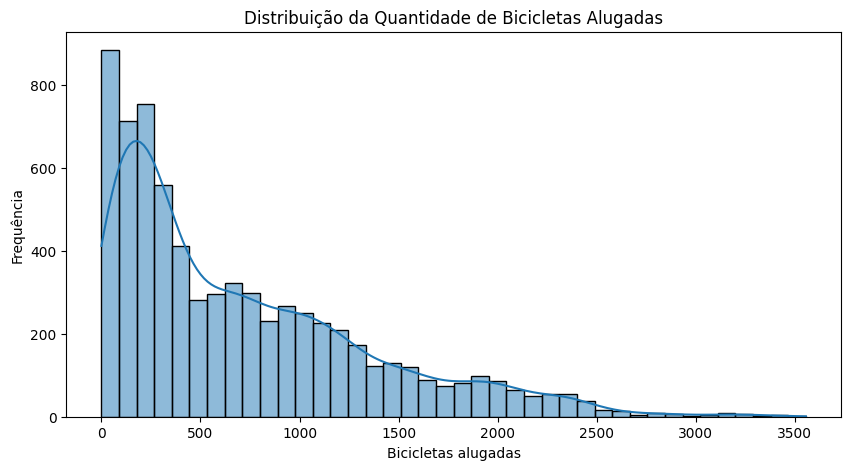

In [ ]:
# Objetivo: Visualizar a distribuição da quantidade de bicicletas alugadas.

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Rented_Bike_Count",
    kde=True
)

plt.title("Distribuição da Quantidade de Bicicletas Alugadas")
plt.xlabel("Bicicletas alugadas")
plt.ylabel("Frequência")

plt.show()

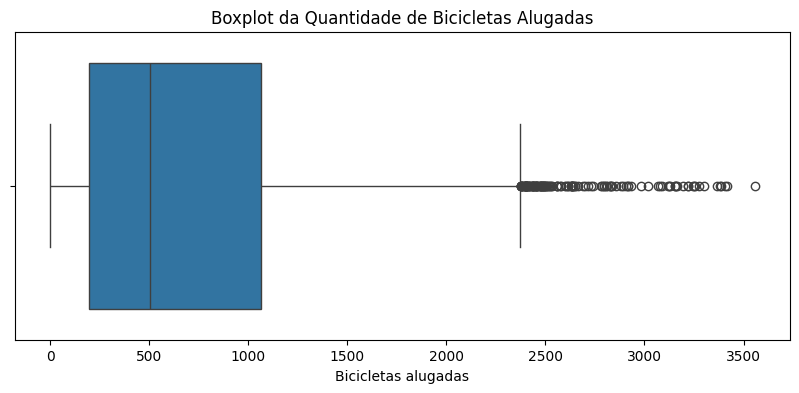

In [ ]:
# Objetivo: Identificar a dispersão e possíveis valores extremos da demanda.

plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="Rented_Bike_Count"
)

plt.title("Boxplot da Quantidade de Bicicletas Alugadas")
plt.xlabel("Bicicletas alugadas")

plt.show()

In [ ]:
# Objetivo: Calcular o limite do boxplot e listar os maiores valores de demanda.
q1_demanda, q3_demanda = df["Rented_Bike_Count"].quantile([0.25, 0.75])
limite_superior = q3_demanda + 1.5 * (q3_demanda - q1_demanda)

print("Limite superior do boxplot:", limite_superior)
print("Horas acima do limite:", (df["Rented_Bike_Count"] > limite_superior).sum())
colunas_contexto = ["Date", "Hour", "Seasons", "Temperature", "Rented_Bike_Count"]
display(df.nlargest(5, "Rented_Bike_Count")[colunas_contexto])

Limite superior do boxplot: 2372.5
Horas acima do limite: 129


,Date,Hour,Seasons,Temperature,Rented_Bike_Count
6665,19/06/2018,18,Summer,24.1,3556
2420,21/06/2018,18,Summer,27.8,3418
2578,12/06/2018,18,Summer,24.9,3404
1323,20/06/2018,18,Summer,27.0,3384
242,04/06/2018,18,Summer,24.4,3380


**O que observamos:** a demanda é assimétrica à direita, com muitas horas de baixa demanda e uma cauda longa até 3.556 bicicletas. O boxplot marca 129 horas acima de cerca de 2.370 bicicletas. As cinco maiores demandas são todas às 18h, em junho.

**Justificativa:** os valores extremos da demanda são mantidos. São picos plausíveis no horário de volta para casa, e não erros de medição, e removê-los ocultaria justamente o comportamento que se quer entender. A influência desses pontos pode ser reavaliada na análise de resíduos do modelo.

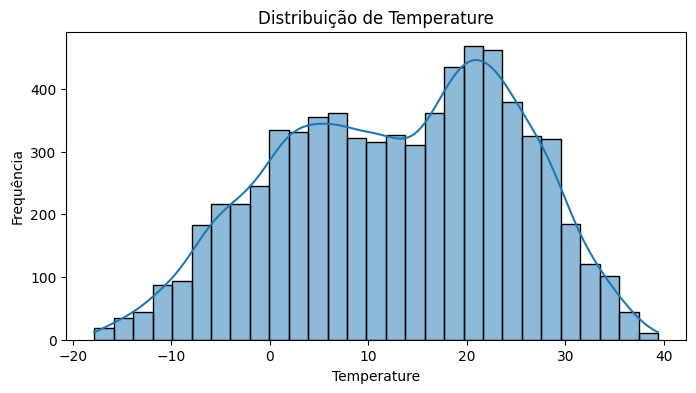

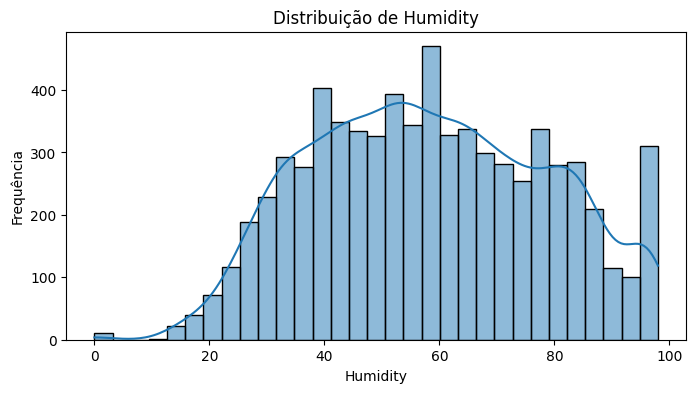

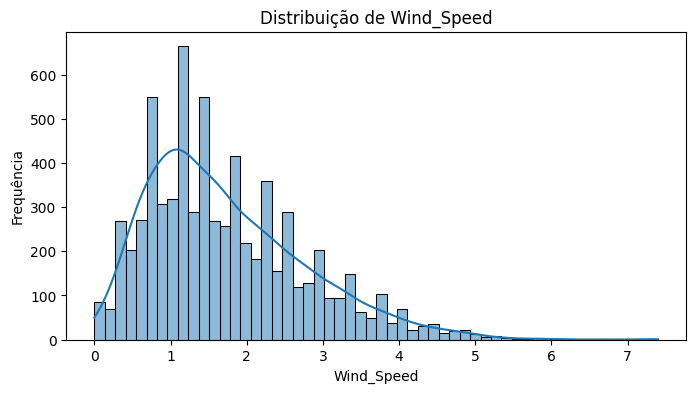

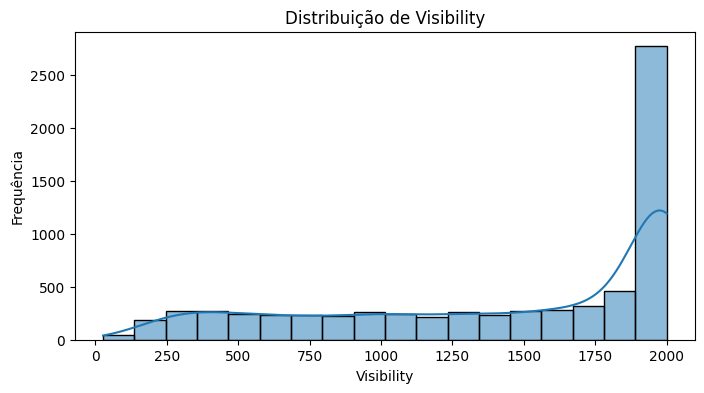

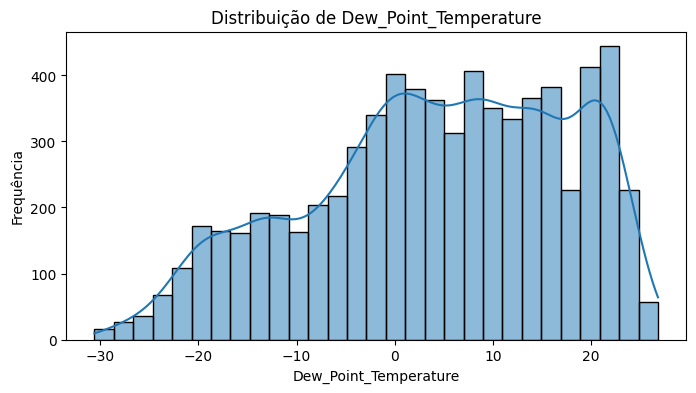

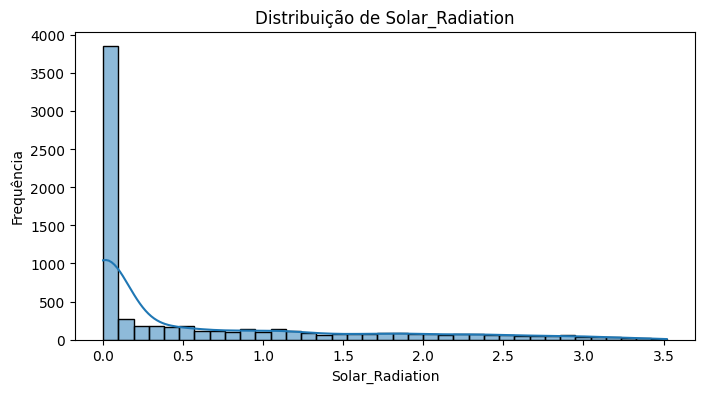

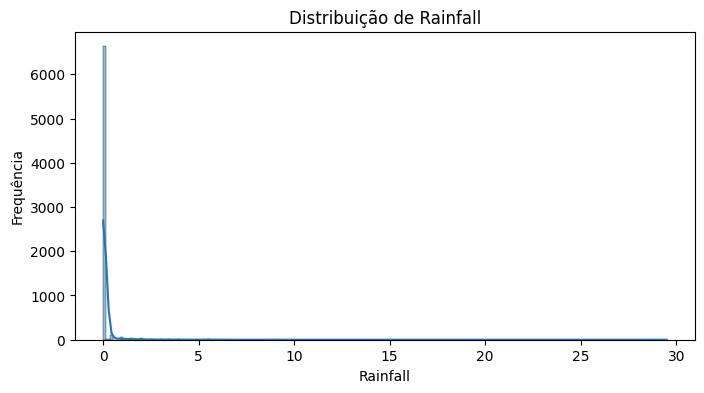

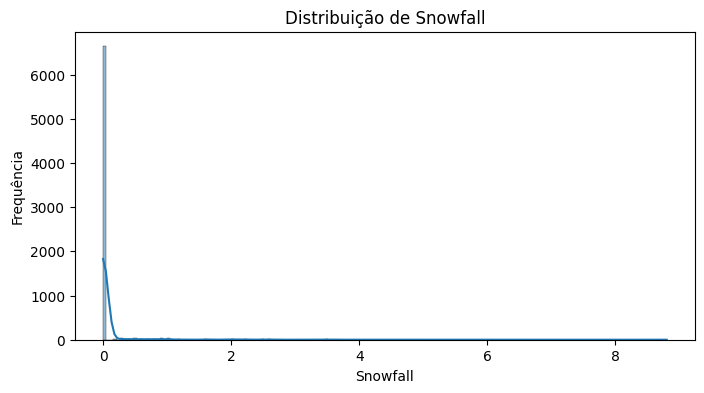

In [ ]:
# Objetivo: Visualizar a distribuição das principais variáveis meteorológicas.

weather_columns = [
    "Temperature",
    "Humidity",
    "Wind_Speed",
    "Visibility",
    "Dew_Point_Temperature",
    "Solar_Radiation",
    "Rainfall",
    "Snowfall"
]

for column in weather_columns:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=column,
        kde=True
    )

    plt.title(f"Distribuição de {column}")
    plt.xlabel(column)
    plt.ylabel("Frequência")

    plt.show()

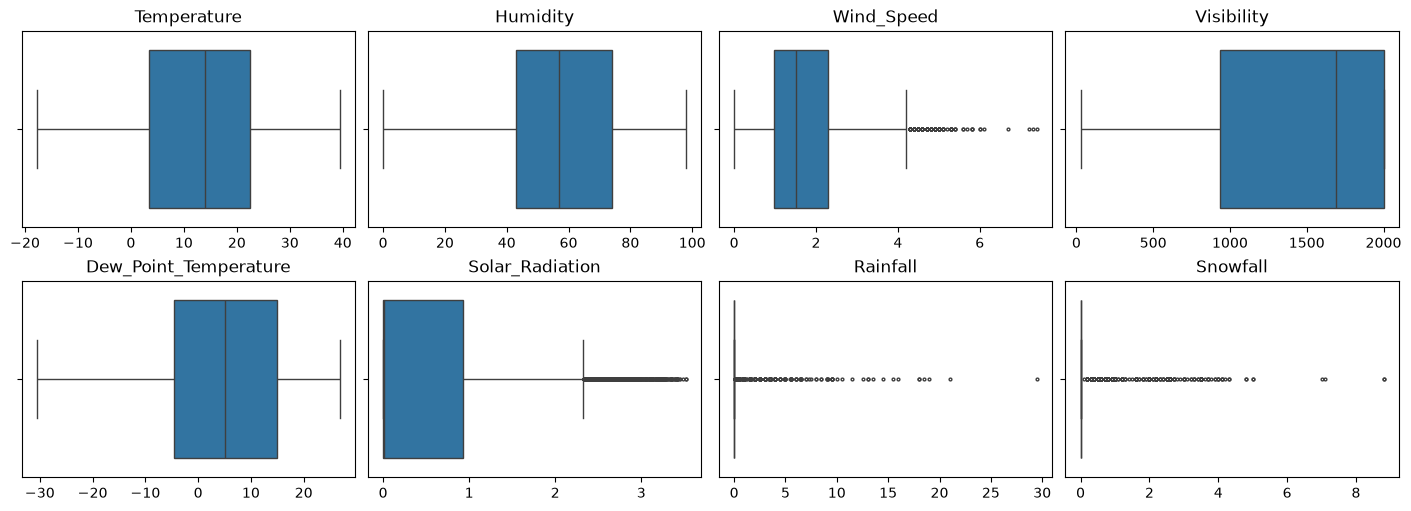

In [ ]:
# Objetivo: Localizar possíveis outliers nas variáveis meteorológicas com boxplots.
fig, axes = plt.subplots(2, 4, figsize=(14, 5), constrained_layout=True)

for ax, column in zip(axes.flat, weather_columns):
    sns.boxplot(data=df, x=column, ax=ax, fliersize=2)
    ax.set_title(column)
    ax.set_xlabel("")

plt.show()

**O que observamos:**

- `Temperature` tem grande amplitude (de −17,8 °C a 39,4 °C), e `Dew_Point_Temperature` tem forma muito parecida, o que antecipa a redundância entre as duas.
- `Humidity` é aproximadamente simétrica. O boxplot não marca nenhum *outlier*: os 10 zeros impossíveis ficam dentro dos bigodes, o que mostra que só o teste de Magnus os revela.
- `Wind_Speed` é assimétrica à direita: predomina o vento fraco.
- `Visibility` acumula valores no teto de 2.000 (cerca de 25% das linhas), provavelmente o limite do instrumento.
- `Solar_Radiation`, `Rainfall` e `Snowfall` têm grande massa no zero. No caso da radiação, o zero é legítimo, pois corresponde à noite.

### Relação entre demanda e variáveis contínuas

Nesta etapa, serão analisadas as relações entre a quantidade de bicicletas alugadas e as principais variáveis contínuas.

Serão utilizados gráficos de dispersão para identificar visualmente tendências, associações, possíveis relações não lineares e valores extremos. Essa análise ajudará a identificar quais variáveis podem apresentar maior potencial explicativo para a demanda.

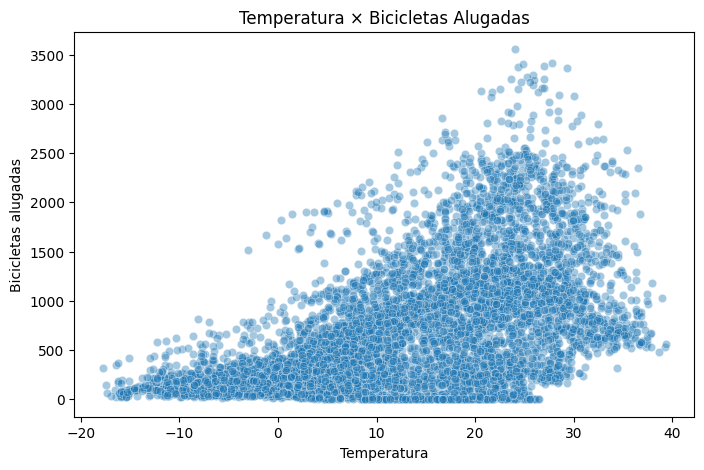

In [ ]:
# Objetivo: Visualizar a relação entre temperatura e quantidade de bicicletas alugadas.

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Temperature",
    y="Rented_Bike_Count",
    alpha=0.4
)

plt.title("Temperatura × Bicicletas Alugadas")
plt.xlabel("Temperatura")
plt.ylabel("Bicicletas alugadas")

plt.show()

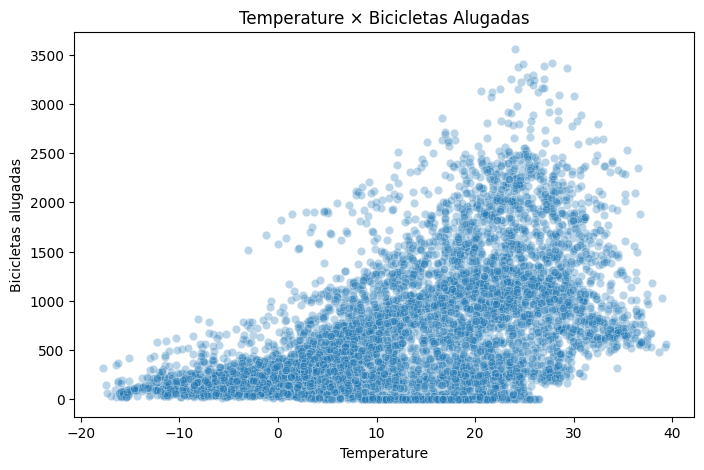

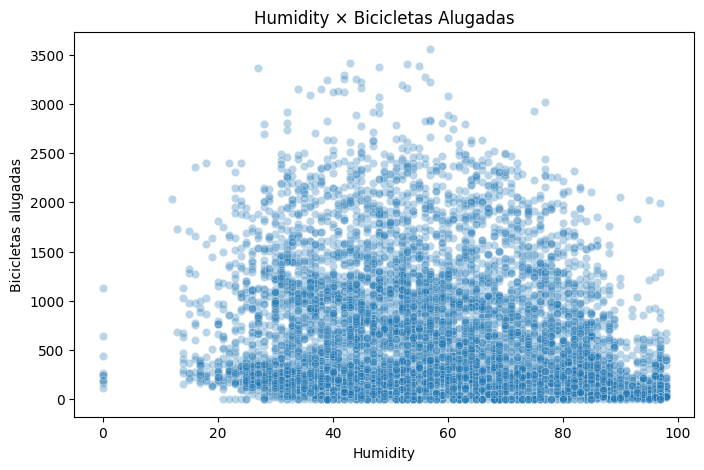

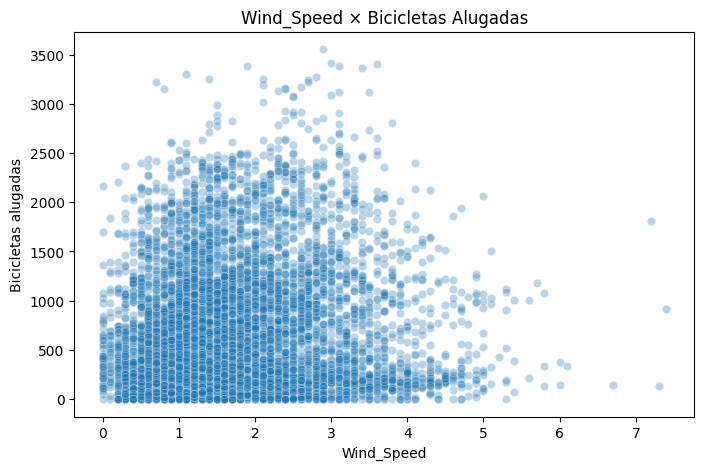

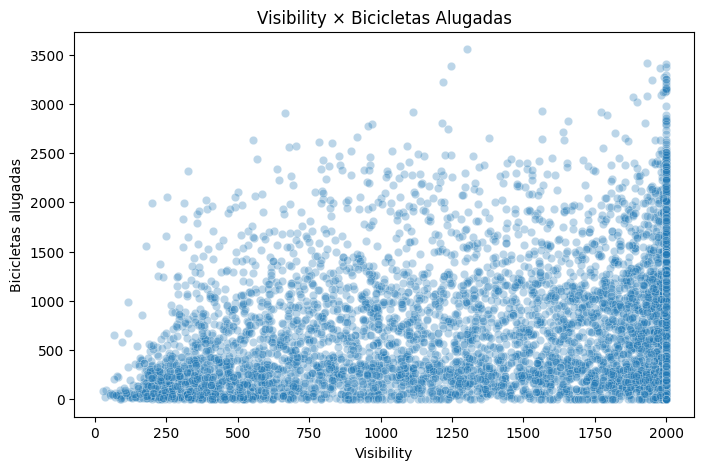

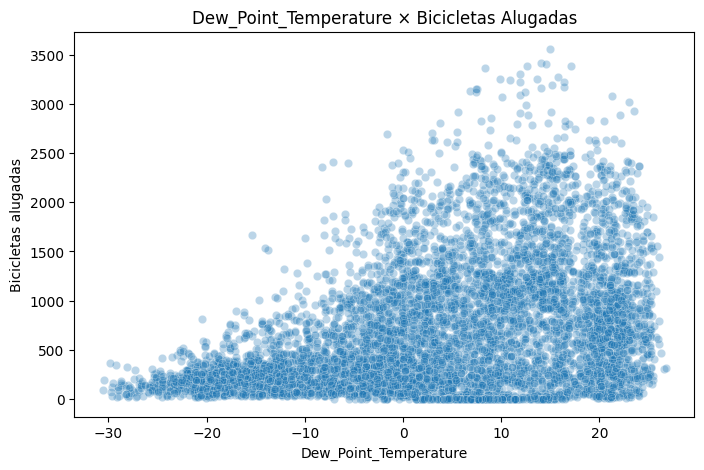

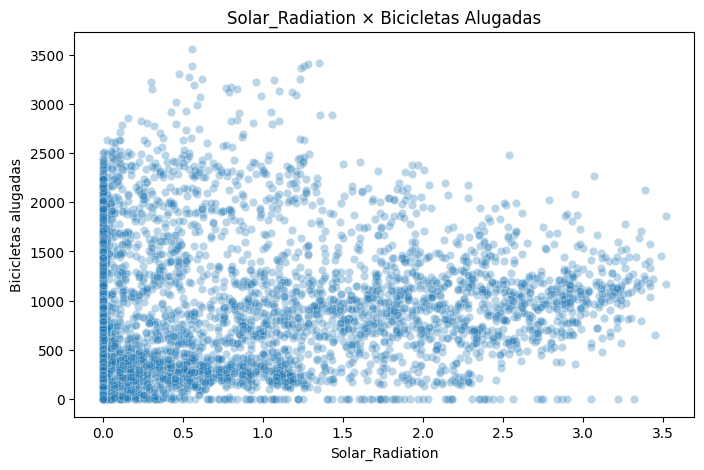

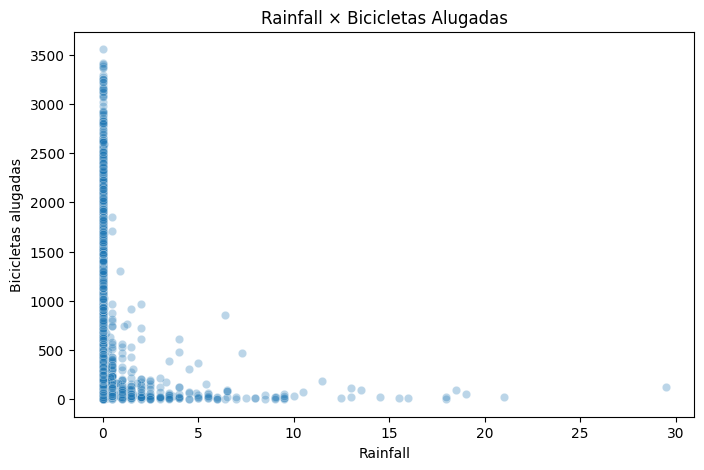

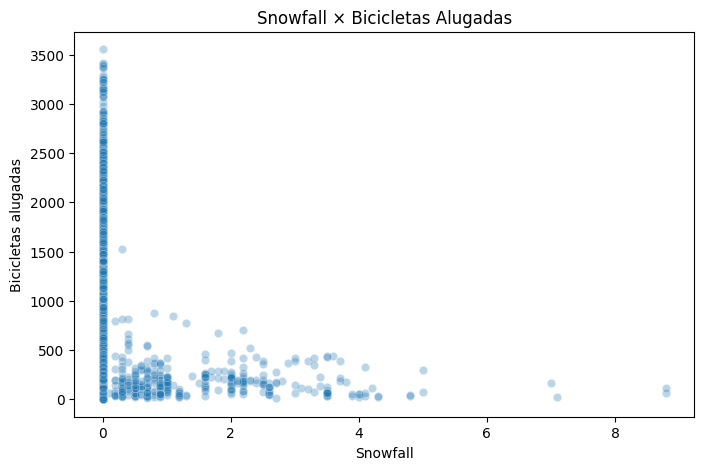

In [ ]:
# Objetivo: Visualizar a relação entre variáveis meteorológicas e a demanda.

for column in weather_columns:
    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x=column,
        y="Rented_Bike_Count",
        alpha=0.3
    )

    plt.title(f"{column} × Bicicletas Alugadas")
    plt.xlabel(column)
    plt.ylabel("Bicicletas alugadas")

    plt.show()

In [ ]:
# Objetivo: Resumir a demanda por faixas das variáveis para ler melhor as tendências.
def resumir_por_faixas(dados, coluna, limites):
    """Resume a demanda dentro de faixas definidas de uma variável contínua.

    Parâmetros:
        dados (DataFrame): dados de origem.
        coluna (str): variável usada para criar as faixas.
        limites (list): limites das faixas.

    Retorna:
        DataFrame com a mediana da demanda e a quantidade de horas em cada faixa.
    """
    faixas = pd.cut(dados[coluna], limites)
    return dados.groupby(faixas, observed=True)["Rented_Bike_Count"].agg(["median", "count"])


limites_por_coluna = {
    "Temperature": [-20, -10, 0, 10, 20, 25, 30, 35, 40],
    "Humidity": [-1, 20, 40, 60, 80, 100],
    "Rainfall": [-0.1, 0, 30],
    "Snowfall": [-0.1, 0, 9],
}
for column, limites in limites_por_coluna.items():
    display(resumir_por_faixas(df_op, column, limites))

,median,count
Temperature,,
"(-20, -10]",115.0,186
"(-10, 0]",177.0,972
"(0, 10]",343.0,1694
"(10, 20]",778.0,1635
"(20, 25]",1017.0,1102
"(25, 30]",1115.5,780
"(30, 35]",944.0,333
"(35, 40]",731.0,72


,median,count
Humidity,,
"(-1, 20]",377.5,102
"(20, 40]",599.5,1420
"(40, 60]",719.0,2239
"(60, 80]",587.0,1821
"(80, 100]",212.0,1192


,median,count
Rainfall,,
"(-0.1, 0.0]",591.0,6367
"(0.0, 30.0]",70.0,407


,median,count
Snowfall,,
"(-0.1, 0.0]",589.0,6407
"(0.0, 9.0]",149.0,367


**O que observamos:** nos gráficos de dispersão, a linha de pontos em zero corresponde às horas com o sistema fechado. Nas tabelas, que usam apenas as horas de operação:

- `Temperature` é a relação mais clara: a mediana sobe de 115 bicicletas (abaixo de −10 °C) para cerca de 1.115 (entre 25 °C e 30 °C) e **recua acima de 30 °C**. Essa curvatura sugere testar um termo quadrático no modelo.
- `Dew_Point_Temperature` tem padrão parecido com o da temperatura, pois as duas se movem juntas.
- `Humidity` forma um arco: a demanda é maior entre 40% e 60% (mediana de 719) e despenca acima de 80% (mediana de 212).
- `Rainfall` e `Snowfall`: a maior diferença está entre *zero* e *não zero*. A mediana cai de 591 para 70 com chuva e de 589 para 149 com neve, embora a neve se misture com o efeito do frio.
- `Solar_Radiation` tem uma massa de pontos no zero, que mistura noites movimentadas e madrugadas vazias. `Wind_Speed` e `Visibility` mostram relação fraca com a demanda.

### Demanda ao longo das horas

A demanda será analisada de acordo com a hora do dia. Como os dados possuem registros horários, essa análise pode revelar padrões de utilização relacionados aos diferentes períodos do dia.

A média da quantidade de bicicletas alugadas será calculada para cada hora, permitindo identificar horários de maior e menor demanda.

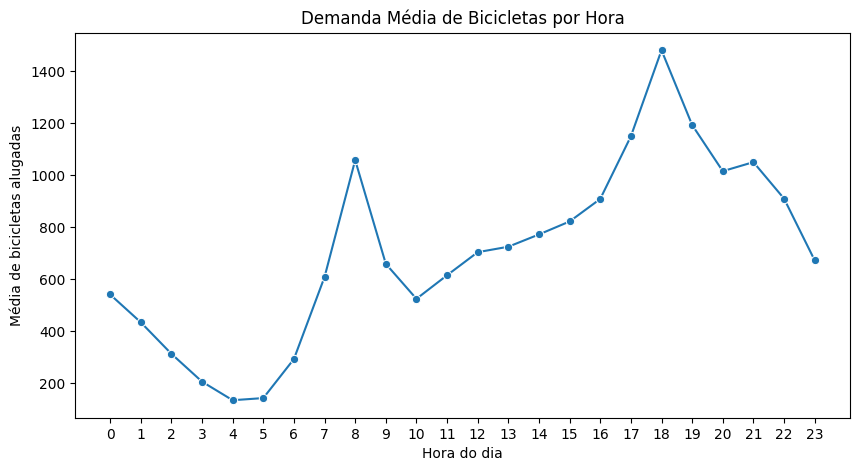

In [ ]:
# Objetivo: Analisar a demanda média de bicicletas para cada hora do dia.

hourly_demand = (
    df.groupby("Hour")["Rented_Bike_Count"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=hourly_demand,
    x="Hour",
    y="Rented_Bike_Count",
    marker="o"
)

plt.title("Demanda Média de Bicicletas por Hora")
plt.xlabel("Hora do dia")
plt.ylabel("Média de bicicletas alugadas")
plt.xticks(range(0, 24))

plt.show()

**O que observamos:** a relação com a hora **não é uma reta**. A demanda média é mínima às 4h (cerca de 133 bicicletas) e tem dois picos, às 8h (1.058) e às 18h (1.480), compatíveis com os horários de ida e volta do trabalho. Por isso, `Hour` deve ser testada como variável categórica no modelo, e não como número.

### Comparação da demanda entre categorias

Os *violin plots* comparam a distribuição da demanda entre as categorias, usando apenas as horas de operação. `Functioning_Day` fica de fora porque, com o sistema fechado, a demanda é sempre zero.

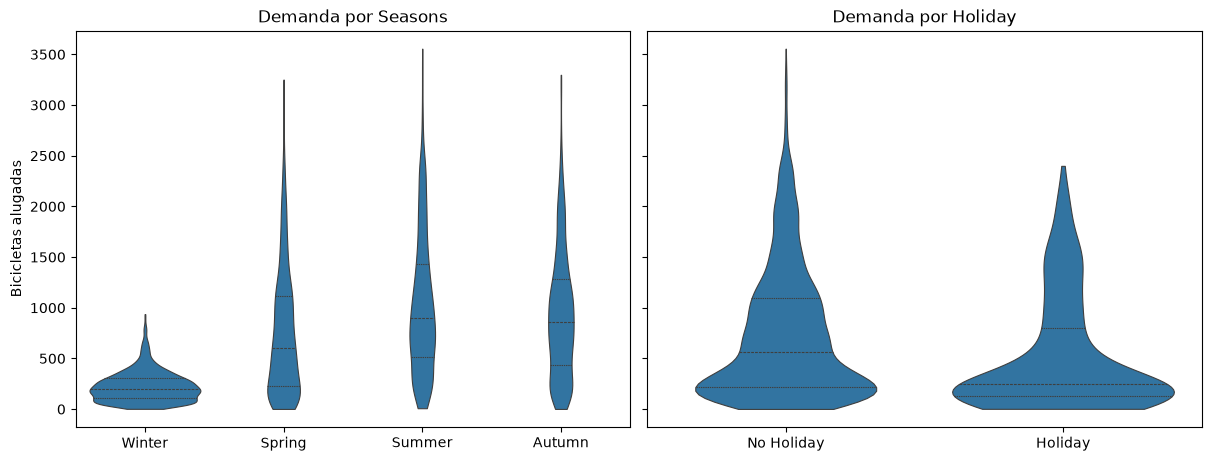

,mean,median,std,count
Seasons,,,,
Autumn,931.0,859.0,620.0,1550
Spring,753.0,606.0,624.0,1729
Summer,1023.0,901.0,682.0,1767
Winter,225.0,204.0,149.0,1728


,mean,median,std,count
Holiday,,,,
Holiday,522.0,250.0,564.0,332
No Holiday,740.0,560.0,643.0,6442


In [ ]:
# Objetivo: Comparar a distribuição da demanda entre estações e entre feriados e não feriados.
def plotar_violino(dados, categoria, ordem, ax):
    """Desenha um violin plot da demanda por categoria, com os quartis marcados.

    Parâmetros:
        dados (DataFrame): dados de origem.
        categoria (str): coluna categórica do eixo horizontal.
        ordem (list): ordem de exibição das categorias.
        ax (Axes): eixo onde desenhar.

    Retorna:
        O próprio eixo recebido, já preenchido.
    """
    sns.violinplot(data=dados, x=categoria, y="Rented_Bike_Count", order=ordem, ax=ax,
                   cut=0, inner="quart", linewidth=0.8)
    ax.set_title(f"Demanda por {categoria}")
    ax.set_xlabel("")
    ax.set_ylabel("Bicicletas alugadas")
    return ax


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, constrained_layout=True)
plotar_violino(df_op, "Seasons", ["Winter", "Spring", "Summer", "Autumn"], axes[0])
plotar_violino(df_op, "Holiday", ["No Holiday", "Holiday"], axes[1])
plt.show()

medidas = ["mean", "median", "std", "count"]
display(df_op.groupby("Seasons")["Rented_Bike_Count"].agg(medidas).round(0))
display(df_op.groupby("Holiday")["Rented_Bike_Count"].agg(medidas).round(0))

In [ ]:
# Objetivo: Verificar se a diferença dos feriados se mantém dentro de cada estação.
display(pd.crosstab(df_op["Holiday"], df_op["Seasons"], normalize="index").round(3))
display(df_op.pivot_table(index="Seasons", columns="Holiday",
                          values="Rented_Bike_Count", aggfunc="median"))

Seasons,Autumn,Spring,Summer,Winter
Holiday,,,,
Holiday,0.244,0.181,0.102,0.473
No Holiday,0.228,0.259,0.269,0.244


Holiday,Holiday,No Holiday
Seasons,,
Autumn,882.0,856.0
Spring,399.0,611.0
Summer,901.0,901.0
Winter,145.0,212.0


**O que observamos:**

- O **inverno** é outro patamar de demanda: mediana de 204 bicicletas, contra 606 na primavera, 859 no outono e 901 no verão, além de dispersão bem menor. A média e o desvio padrão menores no inverno sugerem que a dispersão cresce com o nível da demanda (heterocedasticidade), um ponto de atenção para a regressão.
- Os **feriados** parecem cortar a demanda mais da metade (mediana de 560 para 250), mas 47% das horas de feriado estão no inverno, contra 24% das demais. Dentro das estações, a diferença diminui: no verão e no outono, as medianas são praticamente iguais (901 × 901 e 882 × 856), enquanto na primavera e no inverno há queda de cerca de um terço. Boa parte do efeito geral vem, portanto, da estação em que os feriados caem. Com apenas 18 dias de feriado, esses valores por estação são instáveis.

### Matriz de correlação dos dados

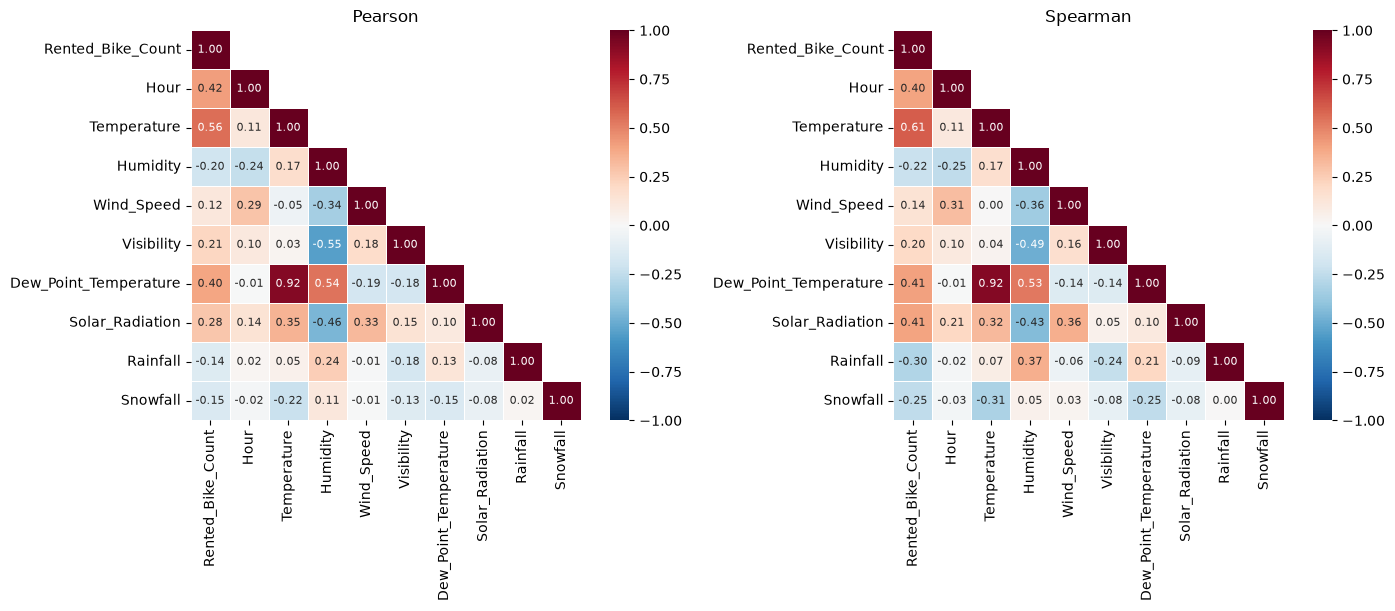

,pearson,spearman
Temperature,0.56,0.61
Solar_Radiation,0.28,0.41
Dew_Point_Temperature,0.40,0.41
Hour,0.42,0.40
Rainfall,-0.14,-0.30
Snowfall,-0.15,-0.25
Humidity,-0.20,-0.22
Visibility,0.21,0.20
Wind_Speed,0.12,0.14


Maior mudança em Pearson sem as 20 linhas inconsistentes: 0.006


In [ ]:
# Objetivo: Calcular e plotar as matrizes de correlação de Pearson e Spearman.
def plotar_correlacao(dados, metodo, ax):
    """Desenha a matriz de correlação anotada, com a metade superior oculta.

    Parâmetros:
        dados (DataFrame): dados de origem; apenas as colunas numéricas são usadas.
        metodo (str): "pearson" ou "spearman".
        ax (Axes): eixo onde desenhar.

    Retorna:
        DataFrame com a matriz de correlação.
    """
    matriz = dados.select_dtypes(include="number").corr(method=metodo)
    mascara = np.triu(np.ones_like(matriz, dtype=bool), k=1)
    sns.heatmap(matriz, mask=mascara, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f",
                annot_kws={"size": 8}, square=True, linewidths=0.5, ax=ax)
    ax.set_title(metodo.capitalize())
    return matriz


fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
pearson = plotar_correlacao(df_op, "pearson", axes[0])
spearman = plotar_correlacao(df_op, "spearman", axes[1])
plt.show()

com_demanda = pd.DataFrame({
    "pearson": pearson["Rented_Bike_Count"],
    "spearman": spearman["Rented_Bike_Count"],
}).drop("Rented_Bike_Count")
display(com_demanda.round(2).sort_values("spearman", key=np.abs, ascending=False))

sem_inconsistentes = df_op[~inconsistente[df_op.index]]
diferenca = (pearson - sem_inconsistentes.select_dtypes(include="number").corr()).abs()
print(f"Maior mudança em Pearson sem as 20 linhas inconsistentes: {diferenca.max().max():.3f}")

**Interpretação:** foram usadas as correlações de Pearson (associação linear) e Spearman (associação monotônica, baseada em postos), nas horas de operação. As 20 linhas inconsistentes praticamente não alteram os resultados.

- **Com a demanda:** `Temperature` lidera nas duas medidas (0,56 e 0,61). Em Pearson, vêm depois `Hour` (0,42) e `Dew_Point_Temperature` (0,40); em Spearman, `Solar_Radiation` e `Dew_Point_Temperature` (ambas 0,41).
- **Spearman bem acima de Pearson, em módulo:** `Rainfall` (−0,14 → −0,30), `Solar_Radiation` (0,28 → 0,41) e `Snowfall` (−0,15 → −0,25). Isso indica relações não lineares, condizentes com a grande massa de zeros vista nos gráficos.
- **Entre as variáveis explicativas:** `Temperature` e `Dew_Point_Temperature` têm r = 0,92, o que indica forte redundância e risco de multicolinearidade na regressão. `Humidity` e `Visibility` têm r = −0,55, e `Humidity` e `Solar_Radiation`, r = −0,46.
- **Cuidado:** correlação não implica causalidade. A correlação positiva entre vento e demanda (0,12) pode refletir apenas o horário, já que `Wind_Speed` e `Hour` também se correlacionam (0,29).
- `Hour` tem correlação moderada, mas o coeficiente subestima sua importância, pois a relação com a demanda tem dois picos e não é linear.

## Seção 2: Fechamento

### Variáveis mais promissoras para o modelo

| Prioridade | Variável | Evidência | Como usar na regressão |
|---|---|---|---|
| **Alta** | `Hour` | Dois picos (8h e 18h); relação não linear | Categórica |
| **Alta** | `Temperature` | Maior correlação (0,56 / 0,61); queda acima de 30 °C | Testar termo quadrático |
| **Alta** | `Rainfall` | Mediana cai de 591 para 70 com chuva | Comparar o volume com um indicador binário |
| **Alta** | `Functioning_Day` | Sistema fechado implica demanda zero | Prever zero nas horas com o sistema fechado |
| **Média** | `Seasons` | Inverno com mediana de 204, contra 606 a 901 nas outras estações | *Dummies*, verificando a sobreposição com a temperatura |
| **Média** | `Humidity` | Queda forte acima de 80% | Testar termo não linear |
| **Média** | `Solar_Radiation` | Spearman 0,41; zero à noite | Testar junto de `Hour`, pela possível redundância |
| **Média** | `Snowfall` | Mediana cai de 589 para 149 com neve | Verificar se acrescenta algo além de temperatura e estação |
| **Baixa** | `Holiday` | Diferença menor dentro das estações; apenas 18 dias | Avaliar na ANOVA |
| **Baixa** | `Wind_Speed`, `Visibility` | Associações fracas (0,12 e 0,21) | Avaliar na ANOVA |
| **Evitar** | `Dew_Point_Temperature` | r = 0,92 com `Temperature`; quase determinada por temperatura e umidade | Retirar, salvo se melhorar o modelo |

### Principais conclusões

1. **Os dados têm erros que não aparecem como valores ausentes:** 20 linhas têm zeros fisicamente impossíveis, identificados pela fórmula de Magnus.
2. **Sistema fechado significa demanda zero:** essas 234 horas não dizem nada sobre a preferência dos usuários e devem ser tratadas à parte.
3. **A demanda varia principalmente com a hora, a temperatura e a estação**, e a chuva provoca uma queda forte, que a correlação de Pearson esconde.
4. **Várias relações não são lineares**, e a dispersão da demanda parece crescer com a média. Portanto, transformações da variável resposta devem ser testadas no modelo.

### Próximos passos

Para a etapa de testes de hipóteses, três perguntas surgem diretamente desta análise: a demanda difere entre as estações? Os feriados alteram a demanda mesmo considerando a estação? Existe relação entre as condições do tempo, como chuva e temperatura, e a demanda?